In [12]:
import torch 
import torch.nn as nn 
import torch.nn.functional as F 
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
random_state = 42
torch.manual_seed(random_state)

In [13]:
training_data = datasets.FashionMNIST(
    root = 'data',
    download=True,
    train = True,
    transform = ToTensor()
)
test_data = datasets.FashionMNIST(
    root = 'data',
    download = True,
    train = False,
    transform = ToTensor()
)
train_loader = DataLoader(training_data, batch_size = 1024, shuffle = True)
test_loader = DataLoader(test_data, batch_size = 1024)

In [14]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super(NeuralNetwork, self).__init__()
        self.flatten = nn.Flatten()
        self.linear1 = nn.Linear(784, 128)
        self.linear2 = nn.Linear(128, 128)
        self.output = nn.Linear(128, 10)
    def forward(self, x):
        x = self.flatten(x)
        x = self.linear1(x)
        x = F.relu(x)
        x = self.linear2(x)
        x = F.relu(x)
        output = self.output(x)
        return output.squeeze(1)
model = NeuralNetwork().to(device)

In [15]:
loss_function = nn.CrossEntropyLoss()
momentum = 0.9
learning_rate = 0.01
optimizer = torch.optim.SGD(model.parameters(), lr = learning_rate, momentum = momentum)

In [16]:
def train(dataloader, model, loss_function, optimizer):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for X, y in dataloader:
        X, y = X.to(device), y.to(device)

        y_pred = model(X)

        loss = loss_function(y_pred, y)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * X.size(0)
        correct += (y_pred.argmax(dim = 1) == y).sum().item()
        total += y.size(0)
    avg_loss = total_loss / total
    accuracy = correct / total * 100
    return avg_loss, accuracy

In [17]:
def test(dataloader, model, loss_function):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)

            y_pred = model(X)
            loss = loss_function(y_pred, y)
            total_loss += loss.item()
            correct += (y_pred.argmax(dim = 1) == y).sum().item()
            total += y.size(0)
    avg_loss = total_loss / total
    accuracy = correct / total * 100
    return avg_loss, accuracy

In [18]:
epochs = 20
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []
for epoch in range(epochs):
    train_loss, train_accuracy = train(train_loader, model, loss_function, optimizer)
    test_loss, test_accuracy = test(test_loader, model, loss_function)

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

    print(
        f'Epoch: [{epoch + 1} / {epochs}]'
        f'Train Loss: {train_loss:.4f} |'
        f'Train Accuracy: {train_accuracy:.2f}% |'
        f'Test Loss: {test_loss:.4f} |'
        f'Test Accuracy: {test_accuracy:.2f}% '
    )

Epoch: [1 / 20]Train Loss: 2.0027 |Train Accuracy: 33.65% |Test Loss: 0.0014 |Test Accuracy: 57.55% 
Epoch: [2 / 20]Train Loss: 0.9987 |Train Accuracy: 64.38% |Test Loss: 0.0008 |Test Accuracy: 69.02% 
Epoch: [3 / 20]Train Loss: 0.7469 |Train Accuracy: 72.21% |Test Loss: 0.0007 |Test Accuracy: 74.25% 
Epoch: [4 / 20]Train Loss: 0.6541 |Train Accuracy: 76.88% |Test Loss: 0.0006 |Test Accuracy: 77.83% 
Epoch: [5 / 20]Train Loss: 0.5935 |Train Accuracy: 79.31% |Test Loss: 0.0006 |Test Accuracy: 79.37% 
Epoch: [6 / 20]Train Loss: 0.5526 |Train Accuracy: 80.67% |Test Loss: 0.0006 |Test Accuracy: 80.36% 
Epoch: [7 / 20]Train Loss: 0.5248 |Train Accuracy: 81.68% |Test Loss: 0.0005 |Test Accuracy: 81.24% 
Epoch: [8 / 20]Train Loss: 0.5022 |Train Accuracy: 82.51% |Test Loss: 0.0005 |Test Accuracy: 81.61% 
Epoch: [9 / 20]Train Loss: 0.4872 |Train Accuracy: 82.90% |Test Loss: 0.0005 |Test Accuracy: 81.89% 
Epoch: [10 / 20]Train Loss: 0.4704 |Train Accuracy: 83.58% |Test Loss: 0.0005 |Test Accurac

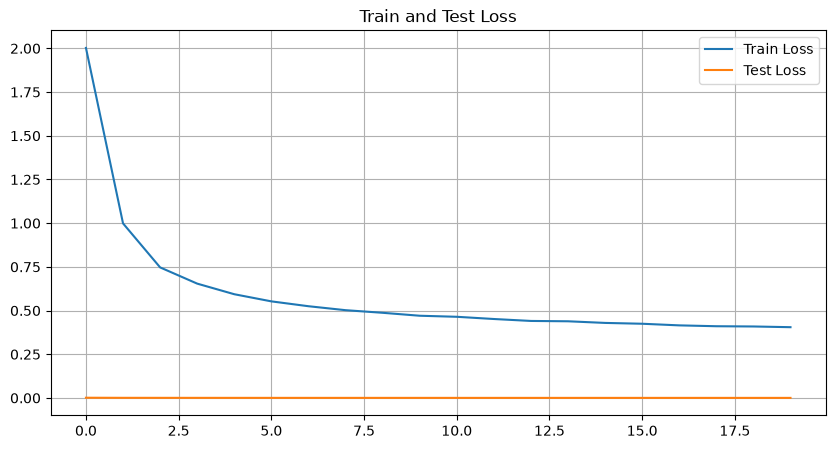

In [19]:
import matplotlib.pyplot as plt
plt.figure(figsize = (10, 5))
plt.plot(train_losses, label = 'Train Loss')
plt.plot(test_losses, label = 'Test Loss')
plt.grid(True)
plt.title('Train and Test Loss')
plt.legend()
plt.show()

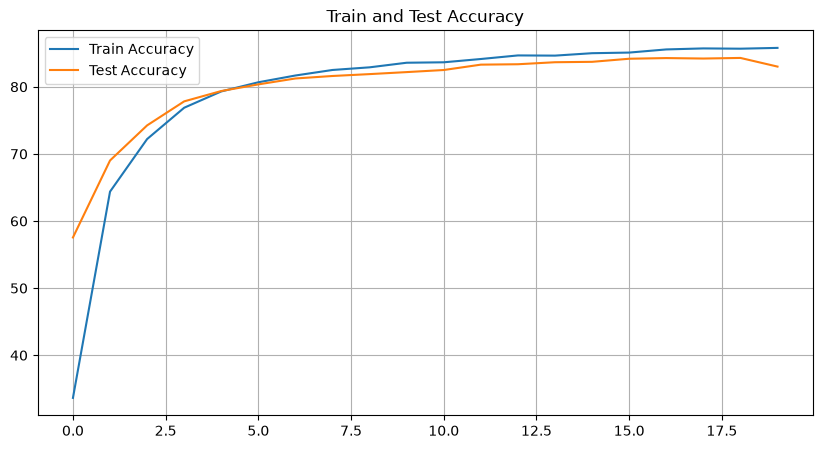

In [20]:
plt.figure(figsize = (10, 5))
plt.plot(train_accuracies, label = 'Train Accuracy')
plt.plot(test_accuracies, label = 'Test Accuracy')
plt.grid(True)
plt.title('Train and Test Accuracy')
plt.legend()
plt.show()